# 07 — Phân tích Hình học Không gian Embedding và Trực quan hóa t-SNE trên Yoochoose

Notebook này đi vào bên trong ma trận **`item_embeddings.npy`** (`10.442` item × `64` chiều) của cả **3 mô hình (`GRU4Rec`, `NARM`, `SASRec`) × 2 random seed (`2024`, `2025`)** trên **Yoochoose `1/32`** để trả lời **Câu hỏi nghiên cứu 2 và 3**:

> **Câu hỏi 2:** *Norm embedding ($\lVert e_i \rVert_2$) có tương quan với tần suất xuất hiện trong train (`train_freq`) trên Yoochoose không? Dấu và độ lớn tương quan Spearman $\rho$ (kèm Bootstrap CI 95%) có lặp lại hiện tượng âm mạnh như Diginetica không?*
>
> **Câu hỏi 3:** *Warm item có tự học được cấu trúc 12 category ngữ nghĩa chuẩn (`1..12`) từ chuỗi click không? Item Cold (20% Option B, chưa huấn luyện) nằm ở đâu so với Warm item cùng category?*

### Thiết kế phân tích chi tiết (10 phần — thích ứng riêng cho đặc thù Yoochoose)
1. Nạp 6 ma trận embedding `(10.442, 64)` và kiểm toán toàn vẹn mapping + trạng thái bất biến của `2.116` Controlled Cold items.
2. Phân tích phân bố **L2 Norm** theo nhóm `Popular / Medium / Rare / Cold` và so sánh nhóm **`Special Offer ('S')`** vs. không `'S'`.
3. Kiểm định **Spearman (`train_freq ↔ norm`)** kèm Bootstrap CI 95% (`1.000` vòng) trên `warm_only` và `all_catalog_incl_cold`.
4. Biểu đồ **Boxplot Norm** và **Scatter `log10(train_freq) ↔ norm`** cho cả 2 seed (`2024`, `2025`).
5. **Cosine Similarity cùng / khác Category (Warm vs. Cold)**: tính riêng trên **12 category ngữ nghĩa thuần (`has_regular_category == True`, 88,0% catalog)** để tránh nhiễu từ `S_only (13)` / `unknown_0 (0)`, đồng thời báo cáo bản đối chứng Full Catalog (`50.000` cặp cân bằng/nhóm + kiểm định Welch t-test & Mann–Whitney U).
6. **Khoảng cách Euclidean & Cosine tới Tâm Category (Centroid)**: so sánh `Popular`, `Medium`, `Rare`, `Cold` trên cả nhóm 12 category chuẩn lẫn full catalog.
7. **Phân tích hình học nâng cao**: Tính dị hướng không gian (**Anisotropy**) và phổ phương sai **PCA** (Effective Dimensionality).
8. **Trực quan hóa t-SNE** (`6.000` item phân tầng, `perplexity = 30`) tô màu theo Popularity Group và theo Category chuẩn `1..12`, đánh dấu Cold item bằng ký hiệu `'X'` cho cả 2 seed.
9. **Đối chiếu chéo trực tiếp Diginetica vs. Yoochoose** về hình học không gian Embedding.
10. Tổng hợp kết luận File 07 & kiểm tra đầu ra bàn giao cho File 08.

## 1. Thiết lập môi trường, nạp 6 ma trận Embedding và kiểm toán toàn vẹn

In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án DA-3.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import get_dataset_paths, ensure_output_dirs
from btl_k03.utils import load_item_mapping, load_yaml
from btl_k03.embedding_analysis import (
    compute_category_centroid_metrics,
    compute_embedding_norms,
    compute_tsne_sample,
    sample_category_cosine_pairs,
    spearman_with_bootstrap_ci,
)

DATASET = "yoochoose"
MODELS = ["gru4rec", "narm", "sasrec"]
MODEL_LABELS = {"gru4rec": "GRU4Rec", "narm": "NARM", "sasrec": "SASRec"}
MODEL_COLORS = {"GRU4REC": "#3182ce", "NARM": "#dd6b20", "SASREC": "#2f855a"}
GROUP_ORDER = ["popular", "medium", "rare", "cold"]
GROUP_COLORS = {"popular": "#e53e3e", "medium": "#3182ce", "rare": "#38a169", "cold": "#718096"}
SEEDS = [2024, 2025]

ensure_output_dirs(DATASET)
YOO_PATHS = get_dataset_paths(DATASET)
DIGI_PATHS = get_dataset_paths("diginetica")
COMMON_CFG = load_yaml(YOO_PATHS["config_dir"] / "common.yaml")
GEOM_CFG = COMMON_CFG["embedding_geometry"]

PROCESSED_DIR = YOO_PATHS["processed_dir"]
RUNS_DIR = YOO_PATHS["runs_dir"]
ITEM_LEVEL_DIR = YOO_PATHS["item_level_dir"]
TABLES_DIR = YOO_PATHS["tables_dir"]
FIGURES_DIR = YOO_PATHS["figures_dir"]
STAT_TESTS_DIR = YOO_PATHS["stat_tests_dir"]

item_mapping = load_item_mapping(PROCESSED_DIR)
embeddings_dict: dict[tuple[str, int], np.ndarray] = {}
item_tables_dict: dict[tuple[str, int], pd.DataFrame] = {}

audit_rows = []
for m in MODELS:
    for seed in SEEDS:
        rdir = RUNS_DIR / m / f"seed_{seed}"
        emb = np.load(rdir / "item_embeddings.npy")
        emb_map = pd.read_csv(rdir / "item_embedding_mapping.csv")
        il_df = pd.read_parquet(ITEM_LEVEL_DIR / f"{m}_seed{seed}.parquet").sort_values(
            "internal_item_id", kind="mergesort"
        ).reset_index(drop=True)

        assert emb.shape == (len(item_mapping), 64), f"Sai kích thước embedding: {emb.shape}"
        assert np.isfinite(emb).all(), f"Embedding chứa NaN/Inf ở {m} seed {seed}"
        assert np.array_equal(emb_map["item_id"].to_numpy(), item_mapping["item_id"].to_numpy())
        assert np.array_equal(il_df["item_id"].to_numpy(), item_mapping["item_id"].to_numpy())
        assert int(il_df.loc[il_df["is_cold"], "train_freq"].max()) == 0

        # Kiểm chứng lại L2 norm khớp item_level
        recalc_norm = compute_embedding_norms(emb)
        assert np.allclose(recalc_norm, il_df["embedding_norm"].to_numpy(), atol=1e-5)

        embeddings_dict[(m, seed)] = emb
        item_tables_dict[(m, seed)] = il_df
        audit_rows.append(
            {
                "model": m.upper(),
                "seed": seed,
                "n_items": emb.shape[0],
                "embedding_dim": emb.shape[1],
                "n_warm": int(il_df["is_trainable_warm"].sum()),
                "n_cold": int(il_df["is_cold"].sum()),
                "n_regular_1_12": int(il_df["has_regular_category"].sum()),
                "status": "OK",
            }
        )

display(pd.DataFrame(audit_rows))
print(f"Đã nạp và kiểm toán sạch 6 ma trận embedding kích thước ({len(item_mapping):,}, 64).")

,model,seed,n_items,embedding_dim,n_warm,n_cold,n_regular_1_12,status
0,GRU4REC,2024,10442,64,8326,2116,9192,OK
1,GRU4REC,2025,10442,64,8326,2116,9192,OK
2,NARM,2024,10442,64,8326,2116,9192,OK
3,NARM,2025,10442,64,8326,2116,9192,OK
4,SASREC,2024,10442,64,8326,2116,9192,OK
5,SASREC,2025,10442,64,8326,2116,9192,OK


Đã nạp và kiểm toán sạch 6 ma trận embedding kích thước (10,442, 64).


## 2. Phân bố L2 Norm theo nhóm Popularity (`Popular / Medium / Rare / Cold`) & nhóm `Special Offer ('S')`

Kiểm tra trực tiếp xem trật tự độ dài vector trên Yoochoose có lặp lại quy luật `Rare > Medium > Popular >> Cold` như Diginetica không, đồng thời kiểm tra L2 Norm riêng của nhóm sản phẩm `Special Offer ('S')`.

In [2]:
norm_rows = []
so_norm_rows = []

for m in MODELS:
    for seed in SEEDS:
        il = item_tables_dict[(m, seed)]
        for grp in GROUP_ORDER:
            sub = il.loc[il["popularity_group"] == grp]
            norm_rows.append(
                {
                    "model": m,
                    "seed": seed,
                    "popularity_group": grp,
                    "n_items": int(len(sub)),
                    "train_freq_mean": float(sub["train_freq"].mean()),
                    "train_freq_median": float(sub["train_freq"].median()),
                    "norm_mean": float(sub["embedding_norm"].mean()),
                    "norm_std": float(sub["embedding_norm"].std(ddof=1)),
                    "norm_median": float(sub["embedding_norm"].median()),
                    "norm_q25": float(sub["embedding_norm"].quantile(0.25)),
                    "norm_q75": float(sub["embedding_norm"].quantile(0.75)),
                }
            )

        warm_il = il.loc[il["is_trainable_warm"]]
        for flag, lbl in [(True, "Special Offer ('S')"), (False, "Non-Special Offer")]:
            sub = warm_il.loc[warm_il["ever_special_offer"] == flag]
            so_norm_rows.append(
                {
                    "model": m.upper(),
                    "seed": seed,
                    "special_offer_group": lbl,
                    "n_items": int(len(sub)),
                    "train_freq_median": float(sub["train_freq"].median()),
                    "norm_mean": float(sub["embedding_norm"].mean()),
                    "norm_median": float(sub["embedding_norm"].median()),
                }
            )

norm_freq_df = pd.DataFrame(norm_rows)
norm_freq_df.to_csv(TABLES_DIR / "norm_frequency.csv", index=False)

norm_seed_summary = (
    norm_freq_df.groupby(["model", "popularity_group"], sort=False)
    .agg(
        n_seeds=("seed", "nunique"),
        norm_mean_across_seeds=("norm_mean", "mean"),
        norm_mean_std_across_seeds=("norm_mean", "std"),
        norm_median_across_seeds=("norm_median", "mean"),
    )
    .reset_index()
)
norm_seed_summary.to_csv(TABLES_DIR / "norm_frequency_seed_summary.csv", index=False)

so_norm_df = pd.DataFrame(so_norm_rows)
so_norm_summary = (
    so_norm_df.groupby(["model", "special_offer_group"], sort=False)[["n_items", "train_freq_median", "norm_mean", "norm_median"]]
    .mean()
    .reset_index()
)
so_norm_summary.to_csv(TABLES_DIR / "norm_special_offer_summary.csv", index=False)

print("=== BẢNG 1A: L2 NORM TRUNG BÌNH QUA 2 SEED THEO NHÓM POPULARITY (YOOCHOOSE) ===")
display(norm_seed_summary.pivot(index="model", columns="popularity_group", values="norm_mean_across_seeds")[GROUP_ORDER])
display(norm_seed_summary)

print("\n=== BẢNG 1B: SO SÁNH L2 NORM GIỮA NHÓM SPECIAL OFFER ('S') VS. KHÔNG 'S' (WARM) ===")
display(so_norm_summary)

=== BẢNG 1A: L2 NORM TRUNG BÌNH QUA 2 SEED THEO NHÓM POPULARITY (YOOCHOOSE) ===


popularity_group,popular,medium,rare,cold
model,,,,
gru4rec,1.1128,1.3354,1.4726,0.1594
narm,1.0781,1.1928,1.2591,0.1592
sasrec,0.8935,1.0741,1.1707,0.1590


,model,popularity_group,n_seeds,norm_mean_across_seeds,norm_mean_std_across_seeds,norm_median_across_seeds
0,gru4rec,popular,2,1.1128,0.0349,1.1076
1,gru4rec,medium,2,1.3354,0.0555,1.3178
2,gru4rec,rare,2,1.4726,0.0646,1.4420
3,gru4rec,cold,2,0.1594,0.0001,0.1590
4,narm,popular,2,1.0781,0.1286,1.0729
5,narm,medium,2,1.1928,0.1623,1.1889
6,narm,rare,2,1.2591,0.1803,1.2555
7,narm,cold,2,0.1592,0.0001,0.1590
8,sasrec,popular,2,0.8935,0.0822,0.8872
9,sasrec,medium,2,1.0741,0.1084,1.0625



=== BẢNG 1B: SO SÁNH L2 NORM GIỮA NHÓM SPECIAL OFFER ('S') VS. KHÔNG 'S' (WARM) ===


,model,special_offer_group,n_items,train_freq_median,norm_mean,norm_median
0,GRU4REC,Special Offer ('S'),604.0000,182.5000,1.0521,1.0253
1,GRU4REC,Non-Special Offer,"7,722.0000",13.0000,1.3436,1.3247
2,NARM,Special Offer ('S'),604.0000,182.5000,1.0578,1.0480
3,NARM,Non-Special Offer,"7,722.0000",13.0000,1.1950,1.1908
4,SASREC,Special Offer ('S'),604.0000,182.5000,0.8408,0.8187
5,SASREC,Non-Special Offer,"7,722.0000",13.0000,1.0773,1.0650


## 3. Kiểm định tương quan Spearman (`train_freq ↔ embedding_norm`) kèm Bootstrap CI 95%

Chạy `1.000` vòng Bootstrap (`confidence = 0,95`) để định lượng tương quan hạng trên:
- **`warm_only`** (kết luận chính, `8.326` warm item).
- **`all_catalog_incl_cold`** (đối chứng phụ, `10.442` item — luôn bị lệch dương giả do cold chưa học có `freq=0, norm≈0,16`).
- **`warm_regular_1_12_only`** (kiểm tra độ bền trên riêng nhóm item có category chuẩn `1..12`).

In [3]:
n_boot = int(GEOM_CFG.get("bootstrap_iterations", 1000))
conf_lvl = float(GEOM_CFG.get("confidence_level", 0.95))

spearman_rows = []
for m in MODELS:
    for seed in SEEDS:
        il = item_tables_dict[(m, seed)]
        warm = il.loc[il["is_trainable_warm"]]
        warm_reg = warm.loc[warm["has_regular_category"]]

        for scope, sub in [
            ("warm_only", warm),
            ("warm_regular_1_12", warm_reg),
            ("all_catalog_incl_cold", il),
        ]:
            res = spearman_with_bootstrap_ci(
                sub["train_freq"],
                sub["embedding_norm"],
                n_bootstrap=n_boot,
                confidence=conf_lvl,
                seed=seed,
            )
            spearman_rows.append(
                {
                    "model": m.upper(),
                    "seed": seed,
                    "catalog_scope": scope,
                    "n_items": res["n"],
                    "spearman_rho": res["rho"],
                    "p_value": res["p_value"],
                    "ci95_low": res["ci_low"],
                    "ci95_high": res["ci_high"],
                }
            )

spearman_df = pd.DataFrame(spearman_rows)
spearman_df.to_csv(STAT_TESTS_DIR / "spearman_results.csv", index=False)

spearman_seed_summary = (
    spearman_df.groupby(["model", "catalog_scope"], sort=False)
    .agg(
        n_seeds=("seed", "nunique"),
        n_items=("n_items", "first"),
        rho_mean=("spearman_rho", "mean"),
        rho_std=("spearman_rho", "std"),
        rho_min=("spearman_rho", "min"),
        rho_max=("spearman_rho", "max"),
    )
    .reset_index()
)
spearman_seed_summary.to_csv(STAT_TESTS_DIR / "spearman_seed_summary.csv", index=False)

print("=== BẢNG 2A: KẾT QUẢ SPEARMAN(TRAIN_FREQ, NORM) TỪNG SEED + BOOTSTRAP CI 95% ===")
display(spearman_df)

print("\n=== BẢNG 2B: TỔNG HỢP SPEARMAN QUA 2 SEED (KẾT LUẬN CHÍNH DÙNG warm_only) ===")
display(spearman_seed_summary)

=== BẢNG 2A: KẾT QUẢ SPEARMAN(TRAIN_FREQ, NORM) TỪNG SEED + BOOTSTRAP CI 95% ===


,model,seed,catalog_scope,n_items,spearman_rho,p_value,ci95_low,ci95_high
0,GRU4REC,2024,warm_only,8326,-0.6990,0.0000,-0.7097,-0.6860
1,GRU4REC,2024,warm_regular_1_12,7327,-0.6450,0.0000,-0.6595,-0.6306
2,GRU4REC,2024,all_catalog_incl_cold,10442,0.1314,0.0000,0.1128,0.1527
3,GRU4REC,2025,warm_only,8326,-0.6615,0.0000,-0.6736,-0.6482
4,GRU4REC,2025,warm_regular_1_12,7327,-0.6033,0.0000,-0.6187,-0.5874
5,GRU4REC,2025,all_catalog_incl_cold,10442,0.1504,0.0000,0.1303,0.1697
6,NARM,2024,warm_only,8326,-0.6157,0.0000,-0.6291,-0.6006
7,NARM,2024,warm_regular_1_12,7327,-0.5664,0.0000,-0.5821,-0.5496
8,NARM,2024,all_catalog_incl_cold,10442,0.1738,0.0000,0.1551,0.1932
9,NARM,2025,warm_only,8326,-0.4850,0.0000,-0.5000,-0.4682



=== BẢNG 2B: TỔNG HỢP SPEARMAN QUA 2 SEED (KẾT LUẬN CHÍNH DÙNG warm_only) ===


,model,catalog_scope,n_seeds,n_items,rho_mean,rho_std,rho_min,rho_max
0,GRU4REC,warm_only,2,8326,-0.6803,0.0265,-0.6990,-0.6615
1,GRU4REC,warm_regular_1_12,2,7327,-0.6242,0.0294,-0.6450,-0.6033
2,GRU4REC,all_catalog_incl_cold,2,10442,0.1409,0.0135,0.1314,0.1504
3,NARM,warm_only,2,8326,-0.5504,0.0924,-0.6157,-0.4850
4,NARM,warm_regular_1_12,2,7327,-0.4979,0.0969,-0.5664,-0.4294
5,NARM,all_catalog_incl_cold,2,10442,0.2070,0.0470,0.1738,0.2403
6,SASREC,warm_only,2,8326,-0.6364,0.0362,-0.6620,-0.6108
7,SASREC,warm_regular_1_12,2,7327,-0.5758,0.0431,-0.6062,-0.5453
8,SASREC,all_catalog_incl_cold,2,10442,0.1632,0.0184,0.1502,0.1763


## 4. Biểu đồ Boxplot L2 Norm và Scatter `log10(train_freq) ↔ embedding_norm` (cả 2 seed)

D:\Temp\ipykernel_30356\3369828035.py:19: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_30356\3369828035.py:20: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / f"norm_boxplot_seed{seed}.png", dpi=160, bbox_inches="tight")
D:\Temp\ipykernel_30356\3369828035.py:22: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / "norm_boxplot.png", dpi=160, bbox_inches="tight")
d:\DL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


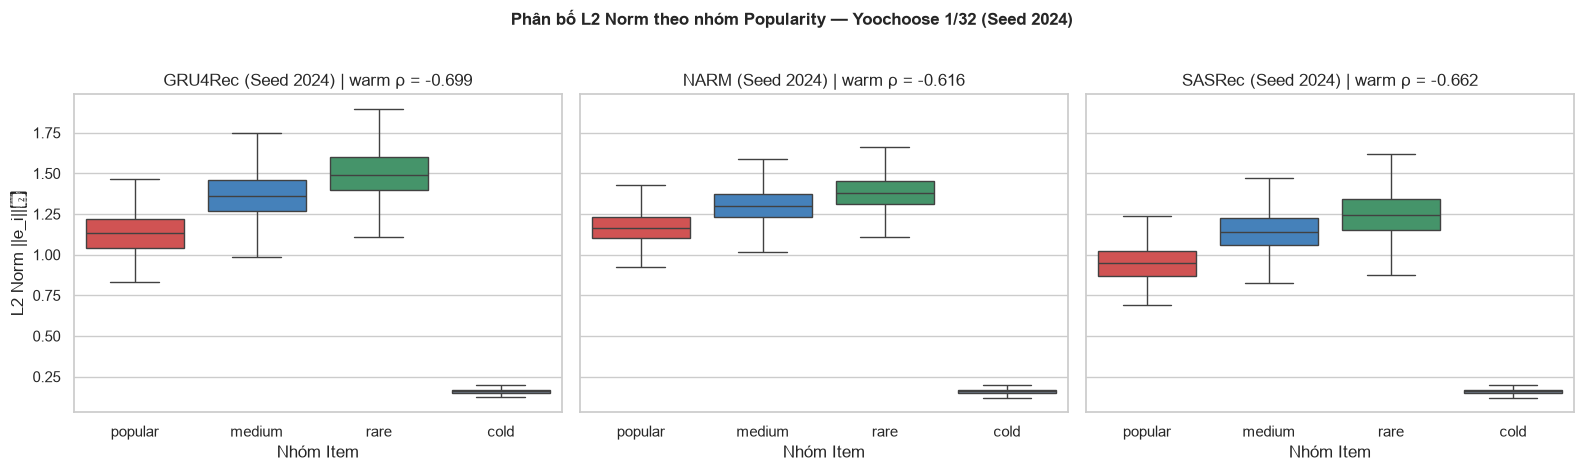

D:\Temp\ipykernel_30356\3369828035.py:55: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_30356\3369828035.py:56: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / f"frequency_norm_scatter_seed{seed}.png", dpi=160, bbox_inches="tight")
D:\Temp\ipykernel_30356\3369828035.py:58: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / "frequency_norm_scatter.png", dpi=160, bbox_inches="tight")


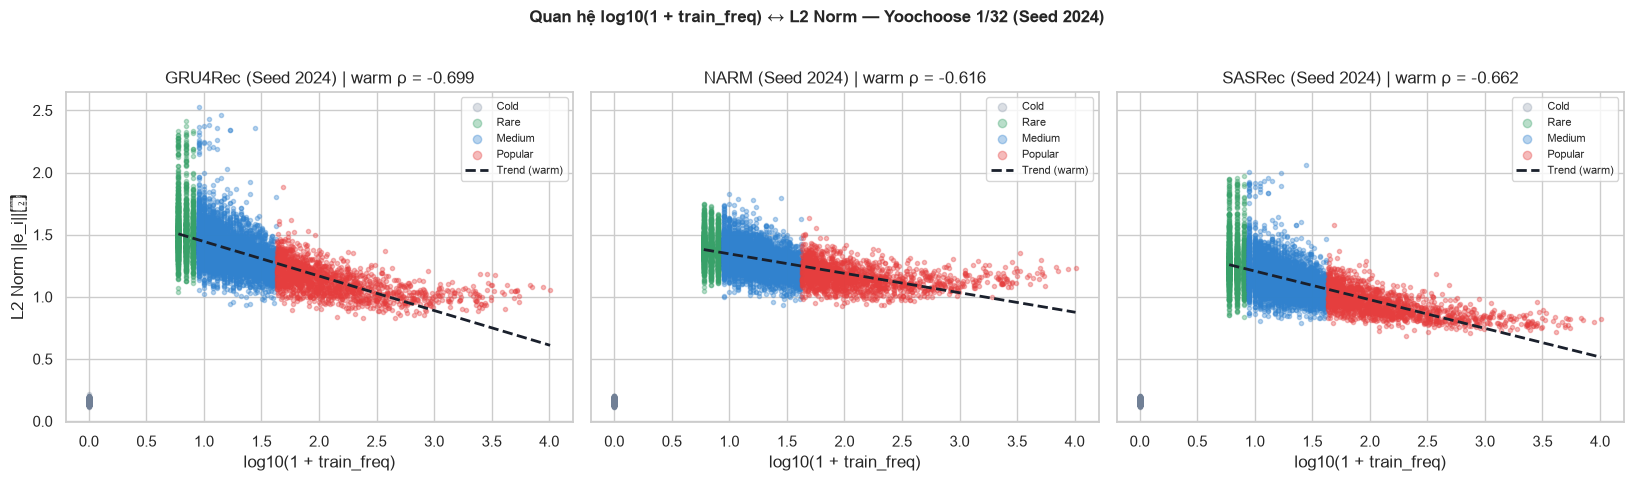

D:\Temp\ipykernel_30356\3369828035.py:19: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_30356\3369828035.py:20: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / f"norm_boxplot_seed{seed}.png", dpi=160, bbox_inches="tight")
D:\Temp\ipykernel_30356\3369828035.py:55: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_30356\3369828035.py:56: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / f"frequency_norm_scatter_seed{seed}.png", dpi=160, bbox_inches="tight")


In [4]:
for seed in SEEDS:
    # 1. Boxplot Norm theo nhóm Popularity
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
    for ax, m in zip(axes, MODELS):
        il = item_tables_dict[(m, seed)]
        sns.boxplot(
            data=il, x="popularity_group", y="embedding_norm",
            hue="popularity_group", order=GROUP_ORDER, hue_order=GROUP_ORDER,
            palette=GROUP_COLORS, legend=False, showfliers=False, ax=ax,
        )
        rho_w = spearman_df.loc[
            (spearman_df["model"] == m.upper()) & (spearman_df["seed"] == seed) & (spearman_df["catalog_scope"] == "warm_only"),
            "spearman_rho",
        ].iloc[0]
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed}) | warm ρ = {rho_w:.3f}")
        ax.set_xlabel("Nhóm Item")
        ax.set_ylabel("L2 Norm ||e_i||₂" if ax is axes[0] else "")
    plt.suptitle(f"Phân bố L2 Norm theo nhóm Popularity — Yoochoose 1/32 (Seed {seed})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"norm_boxplot_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "norm_boxplot.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

    # 2. Scatter log10(1 + train_freq) vs. embedding_norm
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7), sharey=True)
    for ax, m in zip(axes, MODELS):
        il = item_tables_dict[(m, seed)]
        for grp in ["cold", "rare", "medium", "popular"]:
            sub = il.loc[il["popularity_group"] == grp]
            ax.scatter(
                np.log10(sub["train_freq"] + 1.0), sub["embedding_norm"],
                s=9, alpha=0.35 if grp != "cold" else 0.25,
                color=GROUP_COLORS[grp], label=grp.capitalize(), rasterized=True,
            )
        warm = il.loc[il["is_trainable_warm"]]
        # Đường xu hướng bậc 1 trên warm items
        x_w = np.log10(warm["train_freq"].to_numpy() + 1.0)
        y_w = warm["embedding_norm"].to_numpy()
        slope, intercept = np.polyfit(x_w, y_w, 1)
        x_line = np.linspace(x_w.min(), x_w.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color="#1a202c", linewidth=2.0, linestyle="--", label="Trend (warm)")

        rho_w = spearman_df.loc[
            (spearman_df["model"] == m.upper()) & (spearman_df["seed"] == seed) & (spearman_df["catalog_scope"] == "warm_only"),
            "spearman_rho",
        ].iloc[0]
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed}) | warm ρ = {rho_w:.3f}")
        ax.set_xlabel("log10(1 + train_freq)")
        ax.set_ylabel("L2 Norm ||e_i||₂" if ax is axes[0] else "")
        ax.legend(loc="upper right", fontsize=8, markerscale=2)
    plt.suptitle(f"Quan hệ log10(1 + train_freq) ↔ L2 Norm — Yoochoose 1/32 (Seed {seed})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"frequency_norm_scatter_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "frequency_norm_scatter.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

## 5. Phân tích Cosine Similarity cùng Category vs. khác Category (Warm vs. Cold)

**Điểm thiết kế chặt chẽ riêng cho Yoochoose**:
Vì trong `10.442` item có `9.192` item (`88,03%`) sở hữu **12 category ngữ nghĩa chuẩn `1..12`** (`has_regular_category == True`), còn lại là `555` item `S_only (13)` và `702` item `unknown_0 (0)`:
- **Phạm vi chính (`regular_1_12_only`)**: Chỉ lấy mẫu cặp trên các item có category ngữ nghĩa thật `1..12` để đo thuần khiết khả năng tự học cấu trúc danh mục của mô hình (không bị nhiễu bởi nhóm `S_only` hay `unknown_0`).
- **Phạm vi đối chứng (`full_catalog`)**: Chạy thêm trên toàn bộ `10.442` item để kiểm tra độ nhạy.

Mỗi nhóm lấy mẫu cân bằng **`50.000` cặp**, kèm kiểm định Welch t-test và Mann–Whitney U.

=== BẢNG 3A: COSINE SIMILARITY (PHẠM VI CHÍNH: 12 CATEGORY CHUẨN regular_1_12_only) ===


,scope,model,pair_group,n_seeds,n_pairs_per_seed,mean_cosine_across_seeds,mean_cosine_std_across_seeds,median_cosine_across_seeds
0,regular_1_12_only,GRU4REC,warm_same_category,2,50000,0.2287,0.0035,0.2305
1,regular_1_12_only,GRU4REC,warm_diff_category,2,50000,0.1252,0.0021,0.1296
2,regular_1_12_only,GRU4REC,cold_warm_same_category,2,50000,0.0020,0.0010,0.0020
3,regular_1_12_only,GRU4REC,cold_warm_diff_category,2,50000,0.0013,0.0010,0.0012
4,regular_1_12_only,NARM,warm_same_category,2,50000,0.1885,0.0211,0.1884
5,regular_1_12_only,NARM,warm_diff_category,2,50000,0.0831,0.0076,0.0874
6,regular_1_12_only,NARM,cold_warm_same_category,2,50000,-0.0010,0.0009,-0.0003
7,regular_1_12_only,NARM,cold_warm_diff_category,2,50000,-0.0001,0.0001,-0.0001
8,regular_1_12_only,SASREC,warm_same_category,2,50000,0.2300,0.0058,0.2244
9,regular_1_12_only,SASREC,warm_diff_category,2,50000,0.1559,0.0065,0.1622



=== BẢNG 3B: CATEGORY COSINE GAP (WARM vs. COLD — CẢ 2 PHẠM VI) ===


,scope,model,warm_same_vs_diff_mean_gap_mean,warm_same_vs_diff_mean_gap_std,cold_warm_same_vs_diff_mean_gap_mean,cold_warm_same_vs_diff_mean_gap_std,warm_same_vs_diff_mannwhitney_p_max,cold_warm_same_vs_diff_mannwhitney_p_min
0,regular_1_12_only,GRU4REC,0.1035,0.0014,0.0008,0.0000,0.0000,0.2510
1,regular_1_12_only,NARM,0.1054,0.0135,-0.0009,0.0010,0.0000,0.0357
2,regular_1_12_only,SASREC,0.0741,0.0008,-0.0006,0.0006,0.0000,0.1952
3,full_catalog,GRU4REC,0.1108,0.0021,0.0007,0.0007,0.0000,0.2087
4,full_catalog,NARM,0.1120,0.0129,-0.0000,0.0002,0.0000,0.6780
5,full_catalog,SASREC,0.0807,0.0006,0.0004,0.0009,0.0000,0.1520


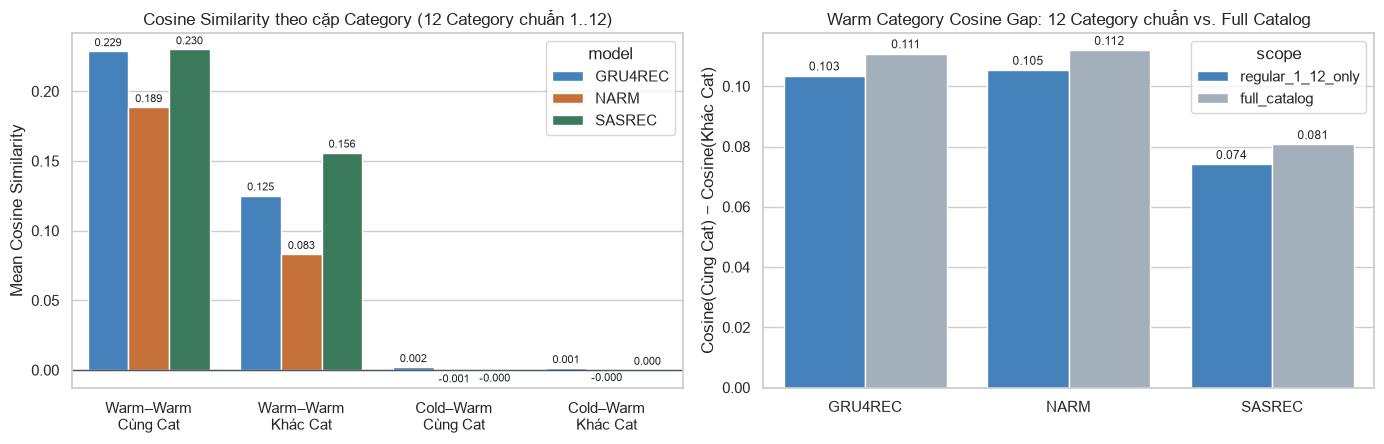

In [5]:
n_pairs = int(GEOM_CFG.get("pair_sample_size_per_group", 50000))
reg_mask = item_mapping["has_regular_category"].to_numpy(dtype=bool)
item_mapping_reg = item_mapping.loc[reg_mask].copy().reset_index(drop=True)

cosine_rows = []
cosine_test_rows = []

for scope_name, use_reg_only in [("regular_1_12_only", True), ("full_catalog", False)]:
    map_sub = item_mapping_reg if use_reg_only else item_mapping
    for m in MODELS:
        for seed in SEEDS:
            emb_full = embeddings_dict[(m, seed)]
            emb_sub = emb_full[reg_mask] if use_reg_only else emb_full

            summary_df, tests_dict = sample_category_cosine_pairs(
                embeddings=emb_sub,
                item_mapping=map_sub,
                n_pairs_per_group=n_pairs,
                seed=seed,
            )
            summary_df.insert(0, "scope", scope_name)
            summary_df.insert(0, "seed", seed)
            summary_df.insert(0, "model", m.upper())
            cosine_rows.append(summary_df)

            cosine_test_rows.append(
                {
                    "model": m.upper(),
                    "seed": seed,
                    "scope": scope_name,
                    **tests_dict,
                }
            )

cosine_df = pd.concat(cosine_rows, ignore_index=True)
cosine_tests_df = pd.DataFrame(cosine_test_rows)
cosine_df.to_csv(TABLES_DIR / "cosine_category.csv", index=False)
cosine_tests_df.to_csv(STAT_TESTS_DIR / "cosine_tests.csv", index=False)

cosine_seed_summary = (
    cosine_df.groupby(["scope", "model", "pair_group"], sort=False)
    .agg(
        n_seeds=("seed", "nunique"),
        n_pairs_per_seed=("n_pairs", "first"),
        mean_cosine_across_seeds=("mean_cosine", "mean"),
        mean_cosine_std_across_seeds=("mean_cosine", "std"),
        median_cosine_across_seeds=("median_cosine", "mean"),
    )
    .reset_index()
)
cosine_seed_summary.to_csv(TABLES_DIR / "cosine_seed_summary.csv", index=False)

cosine_gap_summary = (
    cosine_tests_df.groupby(["scope", "model"], sort=False)[
        ["warm_same_vs_diff_mean_gap", "cold_warm_same_vs_diff_mean_gap", "warm_same_vs_diff_mannwhitney_p", "cold_warm_same_vs_diff_mannwhitney_p"]
    ]
    .agg({"warm_same_vs_diff_mean_gap": ["mean", "std"], "cold_warm_same_vs_diff_mean_gap": ["mean", "std"], "warm_same_vs_diff_mannwhitney_p": "max", "cold_warm_same_vs_diff_mannwhitney_p": "min"})
)
cosine_gap_summary.columns = [f"{a}_{b}" for a, b in cosine_gap_summary.columns]
cosine_gap_summary = cosine_gap_summary.reset_index()
cosine_gap_summary.to_csv(TABLES_DIR / "cosine_gap_seed_summary.csv", index=False)

print("=== BẢNG 3A: COSINE SIMILARITY (PHẠM VI CHÍNH: 12 CATEGORY CHUẨN regular_1_12_only) ===")
display(cosine_seed_summary.loc[cosine_seed_summary["scope"] == "regular_1_12_only"])

print("\n=== BẢNG 3B: CATEGORY COSINE GAP (WARM vs. COLD — CẢ 2 PHẠM VI) ===")
display(cosine_gap_summary)

# Biểu đồ Cosine Similarity (Phạm vi chính: 12 category chuẩn)
plot_cos = cosine_seed_summary.loc[cosine_seed_summary["scope"] == "regular_1_12_only"].copy()
pair_order = ["warm_same_category", "warm_diff_category", "cold_warm_same_category", "cold_warm_diff_category"]
pair_labels = ["Warm–Warm\nCùng Cat", "Warm–Warm\nKhác Cat", "Cold–Warm\nCùng Cat", "Cold–Warm\nKhác Cat"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.barplot(
    data=plot_cos, x="pair_group", y="mean_cosine_across_seeds", hue="model",
    order=pair_order, hue_order=["GRU4REC", "NARM", "SASREC"], palette=MODEL_COLORS, ax=axes[0],
)
axes[0].axhline(0.0, color="#4a5568", linewidth=1)
axes[0].set_xticks(range(4))
axes[0].set_xticklabels(pair_labels)
axes[0].set_xlabel("")
axes[0].set_ylabel("Mean Cosine Similarity")
axes[0].set_title("Cosine Similarity theo cặp Category (12 Category chuẩn 1..12)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8, padding=2)

gap_plot = cosine_gap_summary.copy()
sns.barplot(
    data=gap_plot, x="model", y="warm_same_vs_diff_mean_gap_mean", hue="scope",
    order=["GRU4REC", "NARM", "SASREC"], palette={"regular_1_12_only": "#3182ce", "full_catalog": "#a0aec0"}, ax=axes[1],
)
axes[1].set_title("Warm Category Cosine Gap: 12 Category chuẩn vs. Full Catalog")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cosine(Cùng Cat) − Cosine(Khác Cat)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", fontsize=8.5, padding=2)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "cosine_category_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Khoảng cách Euclidean & Cosine tới Tâm Category (Category Centroid Analysis)

Tính tâm của từng category **chỉ từ các Warm item thuộc category đó**, sau đó đo khoảng cách Euclidean và Cosine từ từng item (`Popular`, `Medium`, `Rare`, `Cold`) tới tâm category của chính nó — báo cáo rõ ràng cho cả **12 category chuẩn (`regular_1_12_only`)** lẫn `full_catalog`.

=== BẢNG 4A: KHOẢNG CÁCH & COSINE TỚI TÂM CATEGORY (12 CATEGORY CHUẨN regular_1_12_only) ===


,scope,model,popularity_group,n_seeds,distance_mean_across_seeds,distance_mean_std_across_seeds,cosine_mean_across_seeds,cosine_mean_std_across_seeds
0,regular_1_12_only,gru4rec,popular,2,1.0888,0.0360,0.3500,0.0020
1,regular_1_12_only,gru4rec,medium,2,1.1672,0.0521,0.4855,0.0040
2,regular_1_12_only,gru4rec,rare,2,1.2484,0.0594,0.5335,0.0056
3,regular_1_12_only,gru4rec,cold,2,0.6705,0.0207,0.0037,0.0028
4,regular_1_12_only,narm,popular,2,1.0227,0.1278,0.3490,0.0159
5,regular_1_12_only,narm,medium,2,1.0716,0.1602,0.4366,0.0244
6,regular_1_12_only,narm,rare,2,1.1121,0.1794,0.4699,0.0309
7,regular_1_12_only,narm,cold,2,0.5413,0.0391,-0.0020,0.0024
8,regular_1_12_only,sasrec,popular,2,0.8902,0.0800,0.3261,0.0013
9,regular_1_12_only,sasrec,medium,2,0.9388,0.0979,0.4872,0.0060



=== BẢNG 4B: CHÊNH LỆCH KHOẢNG CÁCH & COSINE (RARE−POPULAR & COLD−POPULAR) ===


,scope,model,dist_gap_rare_minus_popular,dist_gap_cold_minus_popular,cos_gap_popular_minus_rare,cos_gap_popular_minus_cold
0,regular_1_12_only,GRU4REC,0.1596,-0.4183,-0.1835,0.3463
1,regular_1_12_only,NARM,0.0894,-0.4814,-0.1209,0.3510
2,regular_1_12_only,SASREC,0.0922,-0.3429,-0.2254,0.3275
3,full_catalog,GRU4REC,0.1841,-0.4304,-0.2164,0.3108
4,full_catalog,NARM,0.1028,-0.4883,-0.1205,0.3466
5,full_catalog,SASREC,0.1162,-0.3480,-0.2670,0.2820


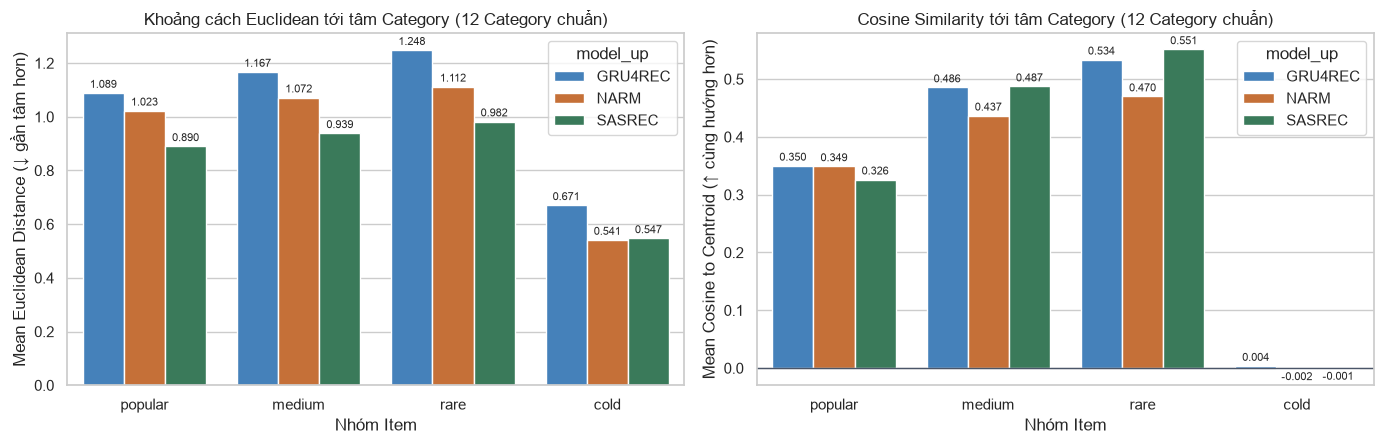

In [6]:
centroid_rows = []
centroid_gap_rows = []

for scope_name, use_reg_only in [("regular_1_12_only", True), ("full_catalog", False)]:
    for m in MODELS:
        for seed in SEEDS:
            il = item_tables_dict[(m, seed)]
            sub_scope = il.loc[il["has_regular_category"]] if use_reg_only else il
            grp_means = {}
            for grp in GROUP_ORDER:
                sub = sub_scope.loc[sub_scope["popularity_group"] == grp]
                d_mean = float(sub["distance_to_category_centroid"].mean())
                c_mean = float(sub["cosine_to_category_centroid"].mean())
                grp_means[grp] = (d_mean, c_mean)
                centroid_rows.append(
                    {
                        "scope": scope_name,
                        "model": m,
                        "seed": seed,
                        "popularity_group": grp,
                        "n_items": int(len(sub)),
                        "distance_mean": d_mean,
                        "distance_median": float(sub["distance_to_category_centroid"].median()),
                        "cosine_mean": c_mean,
                        "cosine_median": float(sub["cosine_to_category_centroid"].median()),
                    }
                )
            centroid_gap_rows.append(
                {
                    "scope": scope_name,
                    "model": m.upper(),
                    "seed": seed,
                    "dist_gap_rare_minus_popular": grp_means["rare"][0] - grp_means["popular"][0],
                    "dist_gap_cold_minus_popular": grp_means["cold"][0] - grp_means["popular"][0],
                    "cos_gap_popular_minus_rare": grp_means["popular"][1] - grp_means["rare"][1],
                    "cos_gap_popular_minus_cold": grp_means["popular"][1] - grp_means["cold"][1],
                }
            )

centroid_df = pd.DataFrame(centroid_rows)
centroid_df.to_csv(TABLES_DIR / "category_centroid.csv", index=False)

centroid_seed_summary = (
    centroid_df.groupby(["scope", "model", "popularity_group"], sort=False)
    .agg(
        n_seeds=("seed", "nunique"),
        distance_mean_across_seeds=("distance_mean", "mean"),
        distance_mean_std_across_seeds=("distance_mean", "std"),
        cosine_mean_across_seeds=("cosine_mean", "mean"),
        cosine_mean_std_across_seeds=("cosine_mean", "std"),
    )
    .reset_index()
)
centroid_seed_summary.to_csv(TABLES_DIR / "category_centroid_seed_summary.csv", index=False)

centroid_gaps_df = pd.DataFrame(centroid_gap_rows)
centroid_gaps_summary = (
    centroid_gaps_df.groupby(["scope", "model"], sort=False)[
        ["dist_gap_rare_minus_popular", "dist_gap_cold_minus_popular", "cos_gap_popular_minus_rare", "cos_gap_popular_minus_cold"]
    ]
    .mean()
    .reset_index()
)
centroid_gaps_summary.to_csv(TABLES_DIR / "category_centroid_gaps.csv", index=False)

print("=== BẢNG 4A: KHOẢNG CÁCH & COSINE TỚI TÂM CATEGORY (12 CATEGORY CHUẨN regular_1_12_only) ===")
display(centroid_seed_summary.loc[centroid_seed_summary["scope"] == "regular_1_12_only"])

print("\n=== BẢNG 4B: CHÊNH LỆCH KHOẢNG CÁCH & COSINE (RARE−POPULAR & COLD−POPULAR) ===")
display(centroid_gaps_summary)

plot_cen = centroid_seed_summary.loc[centroid_seed_summary["scope"] == "regular_1_12_only"].copy()
plot_cen["model_up"] = plot_cen["model"].str.upper()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.barplot(
    data=plot_cen, x="popularity_group", y="distance_mean_across_seeds", hue="model_up",
    order=GROUP_ORDER, hue_order=["GRU4REC", "NARM", "SASREC"], palette=MODEL_COLORS, ax=axes[0],
)
axes[0].set_title("Khoảng cách Euclidean tới tâm Category (12 Category chuẩn)")
axes[0].set_xlabel("Nhóm Item")
axes[0].set_ylabel("Mean Euclidean Distance (↓ gần tâm hơn)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", fontsize=8, padding=2)

sns.barplot(
    data=plot_cen, x="popularity_group", y="cosine_mean_across_seeds", hue="model_up",
    order=GROUP_ORDER, hue_order=["GRU4REC", "NARM", "SASREC"], palette=MODEL_COLORS, ax=axes[1],
)
axes[1].axhline(0.0, color="#4a5568", linewidth=1)
axes[1].set_title("Cosine Similarity tới tâm Category (12 Category chuẩn)")
axes[1].set_xlabel("Nhóm Item")
axes[1].set_ylabel("Mean Cosine to Centroid (↑ cùng hướng hơn)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "category_centroid_distance.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Hình học nâng cao: Tính dị hướng không gian (**Anisotropy**) & Phổ phương sai **PCA**

Kiểm tra cấu trúc hình học tổng thể của không gian embedding 64 chiều (tập Warm `8.326` item):
- **Anisotropy** (Cosine trung bình của 50.000 cặp warm ngẫu nhiên bất kỳ): gần `0` nghĩa là vector tỏa đều các hướng (isotropic); dương cao nghĩa là embedding bị dồn vào một nón hẹp (representation degeneration).
- **Effective Dimensionality (PCA)**: cần bao nhiêu thành phần chính để giải thích `90%` phương sai không gian embedding của mỗi kiến trúc?

,model,seed,random_pair_mean_cosine_anisotropy,pc1_var_pct,top5_pc_var_pct,dims_for_90pct_var,dims_for_95pct_var,effective_rank_pr
0,GRU4REC,2024,0.1167,7.1826,27.6459,36,46,29.7859
1,GRU4REC,2025,0.1204,7.7980,29.7187,34,44,27.0248
2,NARM,2024,0.0764,6.2214,24.3560,37,46,32.6252
3,NARM,2025,0.0890,7.5377,29.4524,30,41,25.9966
4,SASREC,2024,0.1399,5.5641,16.3935,52,57,52.5766
5,SASREC,2025,0.1489,5.9572,17.2851,51,57,50.3043


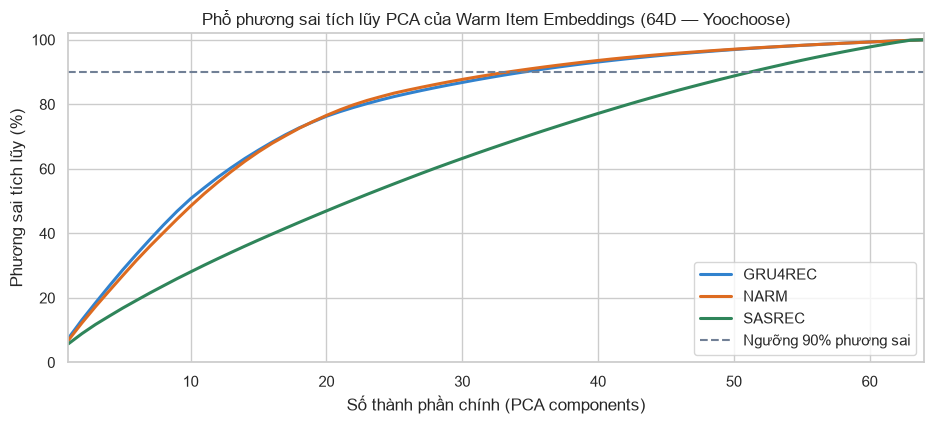

In [7]:
aniso_rows = []
pca_curves: dict[str, np.ndarray] = {}
warm_mask = item_mapping["is_trainable_warm"].to_numpy(dtype=bool)

for m in MODELS:
    cum_list = []
    for seed in SEEDS:
        emb_w = embeddings_dict[(m, seed)][warm_mask].astype(np.float64)
        norms = np.linalg.norm(emb_w, axis=1, keepdims=True)
        unit_w = emb_w / np.clip(norms, 1e-12, None)

        rng = np.random.default_rng(seed)
        idx_a = rng.integers(0, len(unit_w), size=50000)
        idx_b = rng.integers(0, len(unit_w), size=50000)
        valid = idx_a != idx_b
        rand_cos = np.sum(unit_w[idx_a[valid]] * unit_w[idx_b[valid]], axis=1)

        pca = PCA(n_components=emb_w.shape[1], random_state=seed)
        pca.fit(emb_w)
        cum_var = np.cumsum(pca.explained_variance_ratio_)
        cum_list.append(cum_var)

        dim_90 = int(np.searchsorted(cum_var, 0.90) + 1)
        dim_95 = int(np.searchsorted(cum_var, 0.95) + 1)
        # Participation Ratio = (sum lambda)^2 / sum(lambda^2)
        ev = pca.explained_variance_
        eff_rank = float((ev.sum() ** 2) / np.sum(ev ** 2))

        aniso_rows.append(
            {
                "model": m.upper(),
                "seed": seed,
                "random_pair_mean_cosine_anisotropy": float(np.mean(rand_cos)),
                "pc1_var_pct": float(pca.explained_variance_ratio_[0] * 100.0),
                "top5_pc_var_pct": float(cum_var[4] * 100.0),
                "dims_for_90pct_var": dim_90,
                "dims_for_95pct_var": dim_95,
                "effective_rank_pr": eff_rank,
            }
        )
    pca_curves[m.upper()] = np.mean(cum_list, axis=0)

aniso_df = pd.DataFrame(aniso_rows)
aniso_df.to_csv(TABLES_DIR / "embedding_anisotropy_pca.csv", index=False)
display(aniso_df)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
dims = np.arange(1, 65)
for m_up in ["GRU4REC", "NARM", "SASREC"]:
    ax.plot(dims, pca_curves[m_up] * 100.0, linewidth=2.2, color=MODEL_COLORS[m_up], label=m_up)
ax.axhline(90.0, color="#718096", linestyle="--", label="Ngưỡng 90% phương sai")
ax.set_xlabel("Số thành phần chính (PCA components)")
ax.set_ylabel("Phương sai tích lũy (%)")
ax.set_title("Phổ phương sai tích lũy PCA của Warm Item Embeddings (64D — Yoochoose)")
ax.set_xlim(1, 64)
ax.set_ylim(0, 102)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "embedding_pca_spectrum.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Trực quan hóa t-SNE (theo Popularity Group và theo Category chuẩn `1..12`, đánh dấu Cold Item `'X'`)

Chạy t-SNE phân tầng `6.000` item (`1.500` mỗi nhóm `popular / medium / rare / cold`, PCA tiền xử lý 64D → 32D, `perplexity = 30`, `max_iter = 1000`) cho cả 2 seed `2024` và `2025` để kiểm tra độ ổn định trực quan.

> **Lưu ý diễn giải**: t-SNE chỉ bảo toàn cấu trúc lân cận cục bộ; các kết luận định lượng dựa trên Norm, Spearman, Cosine và Centroid ở Mục 2–6.

Hoàn tất t-SNE cho 6 ma trận (36,000 điểm) trong 86.5s.


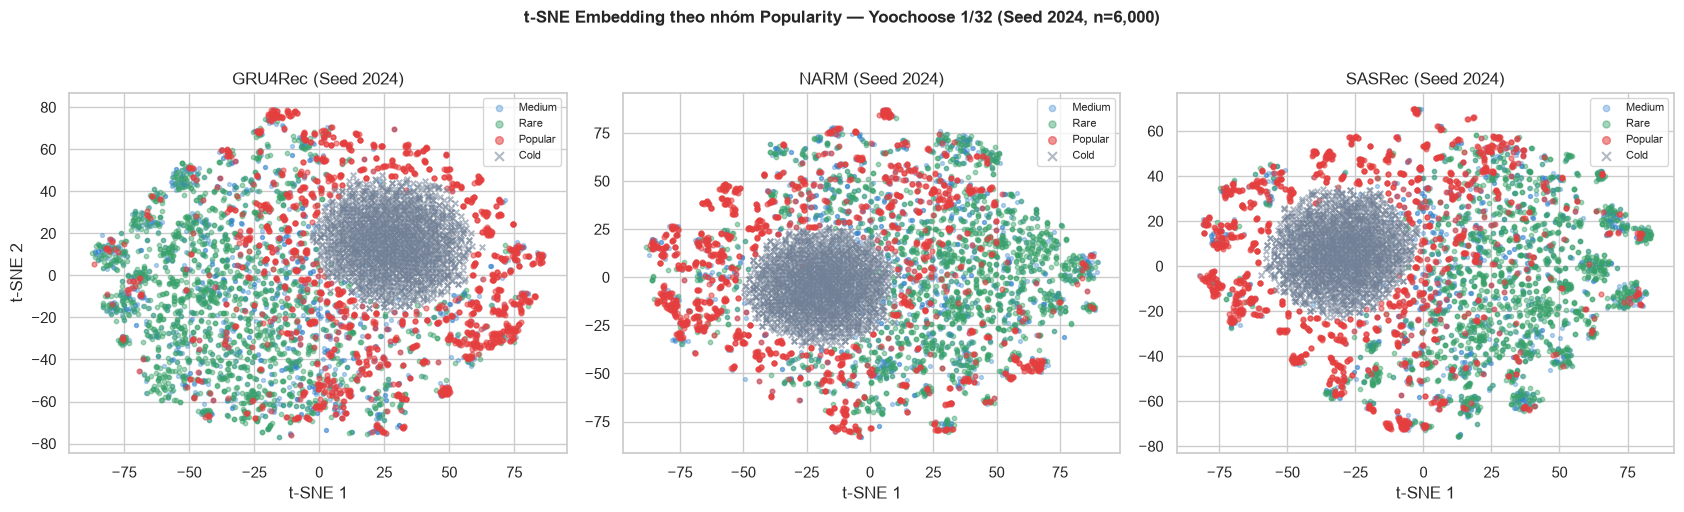

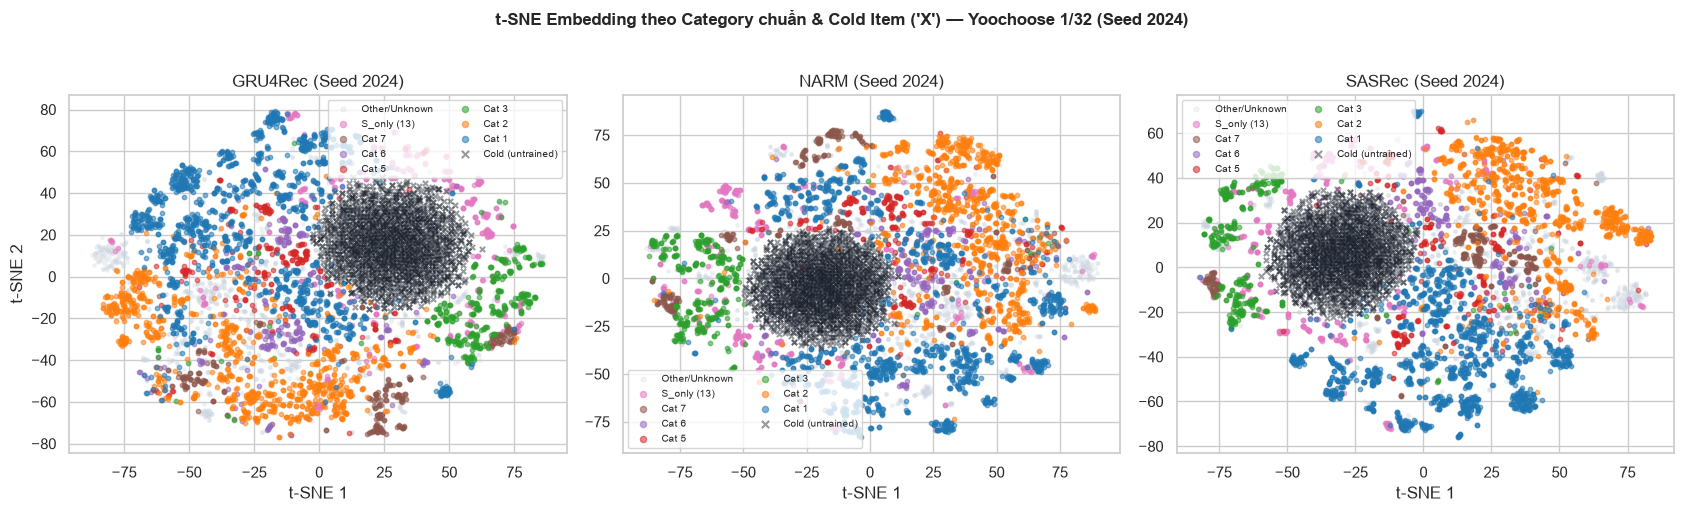

In [8]:
t_tsne = time.perf_counter()
tsne_cfg = GEOM_CFG["tsne"]
tsne_sample_size = int(tsne_cfg.get("sample_size", 6000))
tsne_perplexity = int(tsne_cfg.get("perplexity", 30))
tsne_max_iter = int(tsne_cfg.get("n_iter", 1000))

tsne_frames = []
for m in MODELS:
    for seed in SEEDS:
        emb = embeddings_dict[(m, seed)]
        il = item_tables_dict[(m, seed)]
        ts_df = compute_tsne_sample(
            embeddings=emb,
            item_table=il,
            sample_size=tsne_sample_size,
            perplexity=tsne_perplexity,
            seed=seed,
            n_top_categories=8,
            max_iter=tsne_max_iter,
        )
        # Gán nhãn hiển thị rõ ràng hơn cho category Yoochoose (1..12 vs S_only/Unknown)
        top_reg_cats = (
            il.loc[il["is_trainable_warm"] & il["has_regular_category"], "category_id"]
            .value_counts()
            .head(6)
            .index.tolist()
        )
        ts_df["category_display"] = ts_df.apply(
            lambda r: f"Cat {int(r['category_id'])}"
            if (bool(r["has_regular_category"]) and int(r["category_id"]) in top_reg_cats)
            else ("S_only (13)" if int(r["category_id"]) == 13 else "Other/Unknown"),
            axis=1,
        )
        tsne_frames.append(ts_df)

tsne_all_df = pd.concat(tsne_frames, ignore_index=True)
tsne_all_df.to_parquet(TABLES_DIR / "tsne_coordinates.parquet", index=False, compression="zstd")
print(f"Hoàn tất t-SNE cho 6 ma trận ({len(tsne_all_df):,} điểm) trong {time.perf_counter() - t_tsne:.1f}s.")

for seed in SEEDS:
    # 1. t-SNE theo Popularity Group
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
    for ax, m in zip(axes, MODELS):
        sub = tsne_all_df.loc[(tsne_all_df["model"] == m) & (tsne_all_df["seed"] == seed)]
        for grp, marker, size, alpha in [
            ("medium", "o", 8, 0.35),
            ("rare", "o", 10, 0.45),
            ("popular", "o", 12, 0.55),
            ("cold", "x", 16, 0.55),
        ]:
            g = sub.loc[sub["popularity_group"] == grp]
            ax.scatter(g["tsne_1"], g["tsne_2"], s=size, alpha=alpha, marker=marker, color=GROUP_COLORS[grp], label=grp.capitalize(), rasterized=True)
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed})")
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2" if ax is axes[0] else "")
        ax.legend(loc="best", fontsize=8, markerscale=1.6)
    plt.suptitle(f"t-SNE Embedding theo nhóm Popularity — Yoochoose 1/32 (Seed {seed}, n={tsne_sample_size:,})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"tsne_by_popularity_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "tsne_by_popularity.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

    # 2. t-SNE theo Category chuẩn (đánh dấu Cold bằng 'X' đen)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.0))
    cat_levels = sorted([c for c in tsne_all_df["category_display"].unique() if c.startswith("Cat ")]) + ["S_only (13)", "Other/Unknown"]
    cat_palette = dict(zip(cat_levels, sns.color_palette("tab10", len(cat_levels))))
    cat_palette["Other/Unknown"] = "#cbd5e0"

    for ax, m in zip(axes, MODELS):
        sub = tsne_all_df.loc[(tsne_all_df["model"] == m) & (tsne_all_df["seed"] == seed)]
        warm_s = sub.loc[~sub["is_cold"]]
        cold_s = sub.loc[sub["is_cold"]]
        for c_lbl in reversed(cat_levels):
            g = warm_s.loc[warm_s["category_display"] == c_lbl]
            if len(g) > 0:
                ax.scatter(
                    g["tsne_1"], g["tsne_2"],
                    s=10 if c_lbl != "Other/Unknown" else 6,
                    alpha=0.55 if c_lbl != "Other/Unknown" else 0.25,
                    color=cat_palette[c_lbl], label=c_lbl, rasterized=True,
                )
        ax.scatter(cold_s["tsne_1"], cold_s["tsne_2"], s=14, alpha=0.45, marker="x", color="#1a202c", label="Cold (untrained)", rasterized=True)
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed})")
        ax.set_xlabel("t-SNE 1")
        ax.set_ylabel("t-SNE 2" if ax is axes[0] else "")
        ax.legend(loc="best", fontsize=7.5, markerscale=1.4, ncol=2)
    plt.suptitle(f"t-SNE Embedding theo Category chuẩn & Cold Item ('X') — Yoochoose 1/32 (Seed {seed})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"tsne_by_category_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "tsne_by_category.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

## 9. Đối chiếu chéo Hình học Embedding: **Diginetica vs. Yoochoose**

Đặt trực tiếp các chỉ số hình học cốt lõi của **Yoochoose `1/32`** (trên `warm_only` và 12 category chuẩn) cạnh kết quả đã hoàn thiện của **Diginetica**.

,dataset,model,spearman_freq_norm_warm,norm_popular,norm_rare,norm_cold,cos_warm_same_cat,cos_warm_diff_cat,warm_category_cos_gap,cos_cold_warm_same_cat,centroid_dist_popular,centroid_dist_rare,centroid_dist_cold,centroid_gap_rare_minus_pop
0,Diginetica,GRU4REC,-0.7449,0.9978,1.3574,0.1594,0.6046,0.1754,0.4292,0.0026,0.7000,0.8016,0.9468,0.1016
1,Diginetica,NARM,-0.6675,1.0186,1.2176,0.1593,0.5508,0.1134,0.4374,-0.0006,0.6921,0.7922,0.8476,0.1001
2,Diginetica,SASREC,-0.7066,0.8300,1.0694,0.1593,0.5565,0.1460,0.4105,0.0011,0.5767,0.6857,0.7354,0.1089
3,Yoochoose 1/32,GRU4REC,-0.6803,1.1128,1.4726,0.1594,0.2287,0.1252,0.1035,0.0020,1.0888,1.2484,0.6705,0.1596
4,Yoochoose 1/32,NARM,-0.5504,1.0781,1.2591,0.1592,0.1885,0.0831,0.1054,-0.0010,1.0227,1.1121,0.5413,0.0894
5,Yoochoose 1/32,SASREC,-0.6364,0.8935,1.1707,0.1590,0.2300,0.1559,0.0741,-0.0005,0.8902,0.9824,0.5474,0.0922


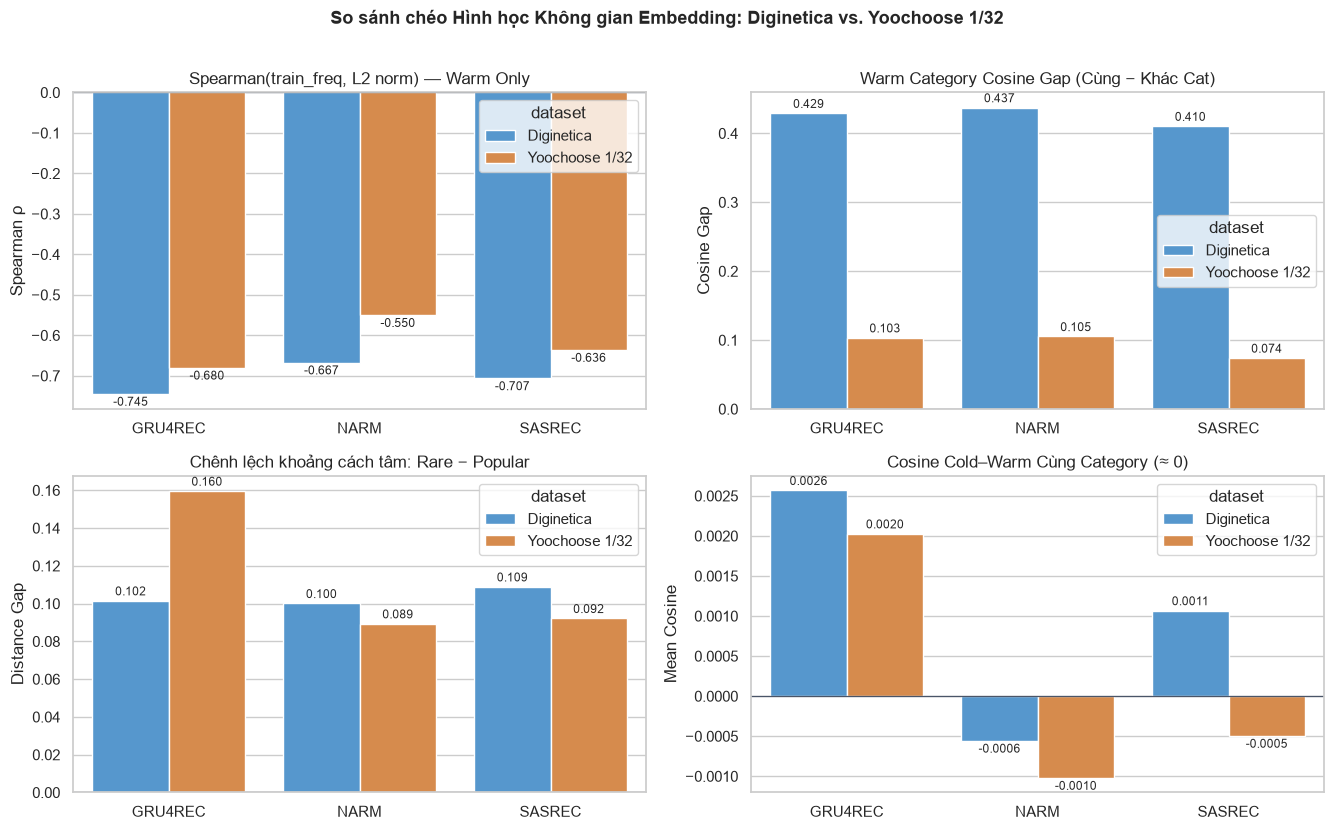

In [9]:
digi_sp = pd.read_csv(DIGI_PATHS["stat_tests_dir"] / "spearman_seed_summary.csv")
digi_norm = pd.read_csv(DIGI_PATHS["tables_dir"] / "norm_frequency_seed_summary.csv")
digi_cos = pd.read_csv(DIGI_PATHS["tables_dir"] / "cosine_seed_summary.csv")
digi_cen = pd.read_csv(DIGI_PATHS["tables_dir"] / "category_centroid_seed_summary.csv")


def build_geom_summary(sp_df, nf_df, cs_df, cn_df, ds_label, cos_scope=None, cen_scope=None):
    sp_w = sp_df.loc[sp_df["catalog_scope"] == "warm_only"].set_index("model")
    nf_p = nf_df.assign(model_up=nf_df["model"].str.upper()).pivot(index="model_up", columns="popularity_group", values="norm_mean_across_seeds")

    cs_sub = cs_df.loc[cs_df["scope"] == cos_scope] if (cos_scope and "scope" in cs_df.columns) else cs_df
    cs_p = cs_sub.pivot(index="model", columns="pair_group", values="mean_cosine_across_seeds")

    cn_sub = cn_df.loc[cn_df["scope"] == cen_scope] if (cen_scope and "scope" in cn_df.columns) else cn_df
    cn_p = cn_sub.assign(model_up=cn_sub["model"].str.upper()).pivot(index="model_up", columns="popularity_group", values="distance_mean_across_seeds")

    rows = []
    for m_up in ["GRU4REC", "NARM", "SASREC"]:
        rows.append(
            {
                "dataset": ds_label,
                "model": m_up,
                "spearman_freq_norm_warm": float(sp_w.loc[m_up, "rho_mean"]),
                "norm_popular": float(nf_p.loc[m_up, "popular"]),
                "norm_rare": float(nf_p.loc[m_up, "rare"]),
                "norm_cold": float(nf_p.loc[m_up, "cold"]),
                "cos_warm_same_cat": float(cs_p.loc[m_up, "warm_same_category"]),
                "cos_warm_diff_cat": float(cs_p.loc[m_up, "warm_diff_category"]),
                "warm_category_cos_gap": float(cs_p.loc[m_up, "warm_same_category"] - cs_p.loc[m_up, "warm_diff_category"]),
                "cos_cold_warm_same_cat": float(cs_p.loc[m_up, "cold_warm_same_category"]),
                "centroid_dist_popular": float(cn_p.loc[m_up, "popular"]),
                "centroid_dist_rare": float(cn_p.loc[m_up, "rare"]),
                "centroid_dist_cold": float(cn_p.loc[m_up, "cold"]),
                "centroid_gap_rare_minus_pop": float(cn_p.loc[m_up, "rare"] - cn_p.loc[m_up, "popular"]),
            }
        )
    return pd.DataFrame(rows)


cross_geom_df = pd.concat(
    [
        build_geom_summary(digi_sp, digi_norm, digi_cos, digi_cen, "Diginetica"),
        build_geom_summary(
            spearman_seed_summary, norm_seed_summary, cosine_seed_summary, centroid_seed_summary,
            "Yoochoose 1/32", cos_scope="regular_1_12_only", cen_scope="regular_1_12_only",
        ),
    ],
    ignore_index=True,
)
cross_geom_df.to_csv(TABLES_DIR / "diginetica_vs_yoochoose_geometry_comparison.csv", index=False)
display(cross_geom_df)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.2))
ds_pal = {"Diginetica": "#4299e1", "Yoochoose 1/32": "#ed8936"}
m_order = ["GRU4REC", "NARM", "SASREC"]

for ax, col, title, ylabel, fmt in [
    (axes[0, 0], "spearman_freq_norm_warm", "Spearman(train_freq, L2 norm) — Warm Only", "Spearman ρ", "%.3f"),
    (axes[0, 1], "warm_category_cos_gap", "Warm Category Cosine Gap (Cùng − Khác Cat)", "Cosine Gap", "%.3f"),
    (axes[1, 0], "centroid_gap_rare_minus_pop", "Chênh lệch khoảng cách tâm: Rare − Popular", "Distance Gap", "%.3f"),
    (axes[1, 1], "cos_cold_warm_same_cat", "Cosine Cold–Warm Cùng Category (≈ 0)", "Mean Cosine", "%.4f"),
]:
    sns.barplot(data=cross_geom_df, x="model", y=col, hue="dataset", order=m_order, palette=ds_pal, ax=ax)
    ax.axhline(0.0, color="#4a5568", linewidth=0.9)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=8.5, padding=2)

plt.suptitle("So sánh chéo Hình học Không gian Embedding: Diginetica vs. Yoochoose 1/32", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "diginetica_vs_yoochoose_geometry_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Kết luận tổng hợp File 07 (Trả lời Câu hỏi 2 & 3) và Kiểm tra đầu ra

In [10]:
yoo_g = cross_geom_df.loc[cross_geom_df["dataset"] == "Yoochoose 1/32"].set_index("model")
findings_07 = [
    (
        "Trật tự L2 Norm theo Popularity",
        f"Rare ({yoo_g['norm_rare'].min():.3f}–{yoo_g['norm_rare'].max():.3f}) > Popular ({yoo_g['norm_popular'].min():.3f}–{yoo_g['norm_popular'].max():.3f}) >> Cold (~{yoo_g['norm_cold'].mean():.3f})",
        "Lặp lại hoàn toàn quy luật trên Diginetica",
    ),
    (
        "Spearman(train_freq, norm) — Warm Only",
        f"GRU4Rec={yoo_g.loc['GRU4REC','spearman_freq_norm_warm']:.4f}, SASRec={yoo_g.loc['SASREC','spearman_freq_norm_warm']:.4f}, NARM={yoo_g.loc['NARM','spearman_freq_norm_warm']:.4f} (CI 95% âm hoàn toàn)",
        "Cả dấu âm mạnh lẫn thứ hạng |ρ| (GRU4Rec > SASRec > NARM) trùng khớp 100% với Diginetica",
    ),
    (
        "Cấu trúc Category của Warm Item (12 Cat chuẩn)",
        f"Warm Category Cosine Gap = {yoo_g['warm_category_cos_gap'].min():.3f}–{yoo_g['warm_category_cos_gap'].max():.3f} (p < 0.0001 ở cả 3 mô hình)",
        "Mô hình tự học cấu trúc category trên Yoochoose (gap nhỏ hơn Diginetica 0.41–0.44 vì Yoochoose chỉ có 12 category thô so với 945 category chi tiết)",
    ),
    (
        "Vị trí Cold Item (20% Option B)",
        f"Cosine Cold–Warm cùng Cat ≈ {yoo_g['cos_cold_warm_same_cat'].mean():.4f} (gần 0); norm ≈ 0.159 và tách khỏi cụm warm trên t-SNE",
        "Khẳng định lại giới hạn của baseline item-ID-only: không có tín hiệu học biểu diễn cho cold item",
    ),
    (
        "Khoảng cách tới Tâm Category",
        f"Gap Rare − Popular = {yoo_g['centroid_gap_rare_minus_pop'].min():+.3f} đến {yoo_g['centroid_gap_rare_minus_pop'].max():+.3f}",
        "Cần kiểm tra kỹ vai trò kiểm soát frequency ở File 08 để nối với Exposure & Hit@20",
    ),
]
findings_07_df = pd.DataFrame(findings_07, columns=["noi_dung", "ket_qua_yoochoose", "doi_chieu_diginetica"])
findings_07_df.to_csv(TABLES_DIR / "file07_key_findings.csv", index=False)
display(findings_07_df)

expected_outputs = [
    TABLES_DIR / "norm_frequency.csv",
    TABLES_DIR / "norm_frequency_seed_summary.csv",
    TABLES_DIR / "cosine_category.csv",
    TABLES_DIR / "cosine_seed_summary.csv",
    TABLES_DIR / "category_centroid.csv",
    TABLES_DIR / "category_centroid_seed_summary.csv",
    TABLES_DIR / "embedding_anisotropy_pca.csv",
    TABLES_DIR / "tsne_coordinates.parquet",
    TABLES_DIR / "diginetica_vs_yoochoose_geometry_comparison.csv",
    STAT_TESTS_DIR / "spearman_results.csv",
    STAT_TESTS_DIR / "spearman_seed_summary.csv",
    STAT_TESTS_DIR / "cosine_tests.csv",
    FIGURES_DIR / "norm_boxplot.png",
    FIGURES_DIR / "frequency_norm_scatter.png",
    FIGURES_DIR / "cosine_category_comparison.png",
    FIGURES_DIR / "category_centroid_distance.png",
    FIGURES_DIR / "tsne_by_popularity.png",
    FIGURES_DIR / "tsne_by_category.png",
    FIGURES_DIR / "diginetica_vs_yoochoose_geometry_comparison.png",
]
missing_out = [str(p) for p in expected_outputs if not p.is_file()]
assert not missing_out, f"Thiếu đầu ra File 07: {missing_out}"
print(f"ĐÃ KIỂM CHỨNG ĐỦ {len(expected_outputs)}/{len(expected_outputs)} FILE ĐẦU RA FILE 07 YOOCHOOSE.")

,noi_dung,ket_qua_yoochoose,doi_chieu_diginetica
0,Trật tự L2 Norm theo Popularity,Rare (1.171–1.473) > Popular (0.894–1.113) >> ...,Lặp lại hoàn toàn quy luật trên Diginetica
1,"Spearman(train_freq, norm) — Warm Only","GRU4Rec=-0.6803, SASRec=-0.6364, NARM=-0.5504 ...",Cả dấu âm mạnh lẫn thứ hạng |ρ| (GRU4Rec > SAS...
2,Cấu trúc Category của Warm Item (12 Cat chuẩn),Warm Category Cosine Gap = 0.074–0.105 (p < 0....,Mô hình tự học cấu trúc category trên Yoochoos...
3,Vị trí Cold Item (20% Option B),Cosine Cold–Warm cùng Cat ≈ 0.0002 (gần 0); no...,Khẳng định lại giới hạn của baseline item-ID-o...
4,Khoảng cách tới Tâm Category,Gap Rare − Popular = +0.089 đến +0.160,Cần kiểm tra kỹ vai trò kiểm soát frequency ở ...


ĐÃ KIỂM CHỨNG ĐỦ 19/19 FILE ĐẦU RA FILE 07 YOOCHOOSE.
